In [1]:
# 0. Setup and load the Iris dataset
# If needed, install packages in a notebook cell with:
# %pip install pandas numpy matplotlib seaborn scikit-learn scipy

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, silhouette_score
)
from sklearn.metrics import pairwise_distances
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

DATA_PATH = "iris.csv"
if not os.path.exists(DATA_PATH) and os.path.exists("/mnt/data/iris.csv"):
    DATA_PATH = "/mnt/data/iris.csv"

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nColumn names:", df.columns.tolist())
print("\nMissing values per column:")
print(df.isnull().sum())

# This notebook expects four numeric measurement columns and one species/label column.
feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
target_col = "species"

# If your column names differ, edit feature_cols and target_col above.
X = df[feature_cols].copy()
y = df[target_col].astype(str).copy()

print("\nSpecies counts:")
print(y.value_counts())


Dataset shape: (150, 5)

First 5 rows:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Column names: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


Cluster counts:
Cluster
1    100
2     49
3      1
Name: count, dtype: int64
Silhouette score: 0.5029


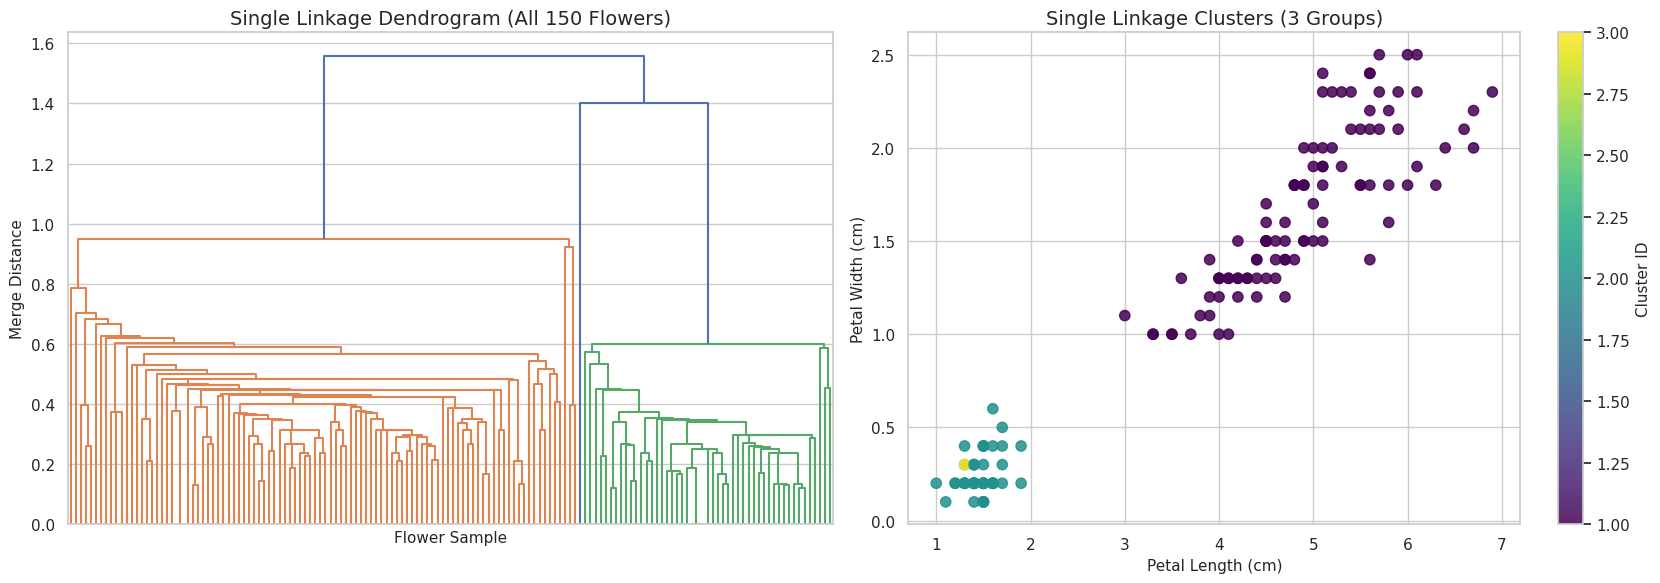

,sepal_length,sepal_width,petal_length,petal_width,species,Cluster
0,5.1,3.5,1.4,0.2,setosa,2
1,4.9,3.0,1.4,0.2,setosa,2
2,4.7,3.2,1.3,0.2,setosa,2
3,4.6,3.1,1.5,0.2,setosa,2
4,5.0,3.6,1.4,0.2,setosa,2
5,5.4,3.9,1.7,0.4,setosa,2
6,4.6,3.4,1.4,0.3,setosa,2
7,5.0,3.4,1.5,0.2,setosa,2
8,4.4,2.9,1.4,0.2,setosa,2
9,4.9,3.1,1.5,0.1,setosa,2


In [8]:
# 7. Hierarchical Clustering: Single Linkage
X_scaled_h = StandardScaler().fit_transform(df[feature_cols])
Z_single = linkage(X_scaled_h, method="single", metric="euclidean")
single_clusters = fcluster(Z_single, t=3, criterion="maxclust")

df_single = df.copy()
df_single["Cluster"] = single_clusters
print("Cluster counts:")
print(df_single["Cluster"].value_counts().sort_index())
print(f"Silhouette score: {silhouette_score(X_scaled_h, single_clusters):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
dendrogram(Z_single, ax=axes[0], no_labels=True, color_threshold=None)
axes[0].set_title("Single Linkage Dendrogram (All 150 Flowers)")
axes[0].set_xlabel("Flower Sample")
axes[0].set_ylabel("Merge Distance")

sc = axes[1].scatter(df_single["petal_length"], df_single["petal_width"],
                     c=single_clusters, cmap="viridis", s=55, alpha=0.85)
axes[1].set_title("Single Linkage Clusters (3 Groups)")
axes[1].set_xlabel("Petal Length (cm)")
axes[1].set_ylabel("Petal Width (cm)")
fig.colorbar(sc, ax=axes[1], label="Cluster ID")
plt.tight_layout()
plt.show()

display(df_single[feature_cols + ["species", "Cluster"]].head(10))
